# MeterTrace — Notebook 01: Data Understanding and EDA

**Project:** MeterTrace: Electricity Theft Detection and Consumption Anomaly Analysis
**Phase:** 1 of 8

## Purpose
Before building any model we need to understand the data honestly. This notebook loads the real
SGCC smart-meter dataset and answers questions like:

- How many customers are there and how many are labelled as theft?
- Which dates are covered, and are the date columns in the right order?
- How much data is missing, and is the missingness the same for theft and normal customers?
- How common are zero readings and extreme readings?
- What happened on 3 October 2014?
- Are there empty customers, identical records, or contradictory labels?
- How do theft and normal customers differ over time?
- How well does the simplest possible score (average consumption) separate the two classes?

## What this notebook does NOT do
- It does **not** change the raw file. We only read it.
- It does **not** remove, fill or cap anything. Cleaning decisions are made in Notebook 02, based on
  the evidence collected here.
- It does **not** split the data or train any model. Every number here is an exploratory,
  whole-dataset statistic.

## Input and outputs
- Input: `data/raw/data.csv`, the original SGCC dataset released with Zheng et al., *"Wide and Deep
  Convolutional Neural Networks for Electricity-Theft Detection to Secure Smart Grids"*,
  IEEE Transactions on Industrial Informatics 14(4), 2018 (doi:10.1109/TII.2017.2785963).
- Outputs: figures saved in `outputs/figures/` (file names start with `01_`).

> **Running on Google Colab:** clone the repository, place `data.csv` in `data/raw/`, and run this
> notebook from the `notebooks/` folder (or from the project root). The paths below work in both cases.

## 0. Setup
We import the libraries and set every path and constant in one place.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

In [2]:
# ---- Paths (work from the notebooks/ folder or from the project root) ----
if Path.cwd().name == "notebooks":
    PROJECT_ROOT = Path.cwd().parent
else:
    PROJECT_ROOT = Path.cwd()

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "data.csv"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# ---- Constants ----
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ID_COLUMN = "CONS_NO"      # customer ID
LABEL_COLUMN = "FLAG"      # 1 = theft, 0 = normal
GLITCH_DATE = pd.Timestamp("2014-10-03")   # system-wide glitch day mentioned in our report

# ---- Plot style (same two colours for the two classes in every chart) ----
NORMAL_COLOR = "#2a78d6"   # blue
THEFT_COLOR = "#eb6834"    # orange
NEUTRAL_COLOR = "#52514e"  # grey for "all customers"
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.max_columns", 12)

print("pandas", pd.__version__, "| numpy", np.__version__)
print("Data file:", DATA_PATH.relative_to(PROJECT_ROOT))
print("Data file exists:", DATA_PATH.exists())

pandas 3.1.0 | numpy 2.5.4
Data file: data/raw/data.csv
Data file exists: True


## 1. Load and inspect the dataset
The file has one row per customer. The first two columns are the customer ID and the label;
every other column is one day of electricity consumption in kWh.

In [3]:
raw_data = pd.read_csv(DATA_PATH)

print("Shape (rows, columns):", raw_data.shape)
raw_data.head()

Shape (rows, columns): (42372, 1036)


,CONS_NO,FLAG,2014/1/1,2014/1/10,2014/1/11,2014/1/12,...,2016/9/4,2016/9/5,2016/9/6,2016/9/7,2016/9/8,2016/9/9
0,0387DD8A07E07FDA6271170F86AD9151,1,NaN,NaN,NaN,NaN,...,27.22,18.05,26.47,18.75,17.84,14.92
1,01D6177B5D4FFE0CABA9EF17DAFC2B84,1,NaN,NaN,NaN,NaN,...,0.00,0.00,0.00,0.00,0.00,0.00
2,4B75AC4F2D8434CFF62DB64D0BB43103,1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN
3,B32AC8CC6D5D805AC053557AB05F5343,1,NaN,NaN,NaN,NaN,...,26.80,18.57,14.59,12.82,19.37,15.92
4,EDFC78B07BA2908B3395C4EB2304665E,1,2.9,3.42,3.81,4.58,...,12.23,14.68,16.35,18.14,18.41,17.31


In [4]:
print("First 5 column names:", list(raw_data.columns[:5]))
print("Last 3 column names: ", list(raw_data.columns[-3:]))
print()
print("Column data types:")
print(raw_data.dtypes.value_counts())
print()
print("Memory used by the table: %.0f MB" % (raw_data.memory_usage(deep=True).sum() / 1e6))

First 5 column names: ['CONS_NO', 'FLAG', '2014/1/1', '2014/1/10', '2014/1/11']
Last 3 column names:  ['2016/9/7', '2016/9/8', '2016/9/9']

Column data types:
float64    1034
str           1
int64         1
Name: count, dtype: int64

Memory used by the table: 354 MB


**What we see.** The table has 42,372 rows and 1,036 columns: `CONS_NO` (text ID), `FLAG`
(integer label) and 1,034 columns of daily readings (decimal numbers, in kWh). Even the first
five rows contain many `NaN` (missing) values. The column names are listed in **text order**
(`2014/1/1`, `2014/1/10`, `2014/1/11`, …), not in date order. We fix that in Section 3.

## 2. Verify customer count, labels and daily columns
We compare the numbers computed from the file with the numbers stated in our submitted report.
The "Report says" column is copied from the report; the "Dataset" column is computed by code.

In [5]:
date_columns = [column for column in raw_data.columns if column not in [ID_COLUMN, LABEL_COLUMN]]

n_customers = len(raw_data)
n_duplicate_ids = raw_data[ID_COLUMN].duplicated().sum()
label_counts = raw_data[LABEL_COLUMN].value_counts().sort_index()
n_normal = label_counts[0]
n_theft = label_counts[1]
theft_share = n_theft / n_customers
all_normal_accuracy = n_normal / n_customers

report_check = pd.DataFrame({
    "Report says": ["42,372", "none", "3,615", "38,757", "8.5%", "91.5%", "1,034"],
    "Dataset": [
        f"{n_customers:,}",
        f"{n_duplicate_ids}",
        f"{n_theft:,}",
        f"{n_normal:,}",
        f"{theft_share:.2%}",
        f"{all_normal_accuracy:.2%}",
        f"{len(date_columns):,}",
    ],
}, index=[
    "Customers",
    "Duplicate customer IDs",
    "Theft customers (FLAG = 1)",
    "Normal customers (FLAG = 0)",
    "Theft share",
    "Accuracy of predicting 'normal' for everyone",
    "Daily consumption columns",
])
report_check

,Report says,Dataset
Customers,"42,372","42,372"
Duplicate customer IDs,none,0
Theft customers (FLAG = 1),"3,615","3,615"
Normal customers (FLAG = 0),"38,757","38,757"
Theft share,8.5%,8.53%
Accuracy of predicting 'normal' for everyone,91.5%,91.47%
Daily consumption columns,"1,034","1,034"


### Class balance
Only a small share of customers is labelled as theft. This is why **accuracy is a misleading
metric** for this project: a useless model that calls everyone "normal" already scores the
accuracy shown in the table above.

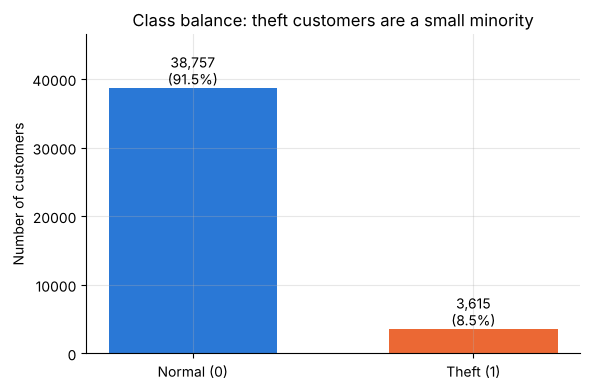

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
class_names = ["Normal (0)", "Theft (1)"]
class_counts = [n_normal, n_theft]
bars = ax.bar(class_names, class_counts, color=[NORMAL_COLOR, THEFT_COLOR], width=0.6)
for bar, count in zip(bars, class_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, count, f"{count:,}\n({count / n_customers:.1%})",
            ha="center", va="bottom")
ax.set_ylabel("Number of customers")
ax.set_title("Class balance: theft customers are a small minority")
ax.set_ylim(0, n_normal * 1.2)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_class_balance.png", dpi=120)
plt.show()

### Are theft customers stored first?
Our report noted that all theft customers are listed first in the file. If that is true, any
split that takes "the last X% of rows" (for example Keras `validation_split`) would contain
**no theft customers at all**. We check the position of the first normal customer.

In [7]:
labels_in_file_order = raw_data[LABEL_COLUMN].to_numpy()
first_normal_row = int(np.argmax(labels_in_file_order == 0))

print("Row position of the first normal customer:", first_normal_row)
print("All rows before it are theft:", bool((labels_in_file_order[:first_normal_row] == 1).all()))
print("Any theft rows after it:     ", bool((labels_in_file_order[first_normal_row:] == 1).any()))

Row position of the first normal customer: 3615
All rows before it are theft: True
Any theft rows after it:      False


**What we see.**
- All seven numbers match our submitted report.
- The first normal customer is at row position 3,615. So rows 0 to 3,614 are exactly the 3,615 theft
  customers, and no theft customer appears after them.

**Why it matters.** In Notebook 02 we must **shuffle and stratify** when splitting customers. We must
also never use Keras `validation_split`, which takes the last rows of the array without shuffling and
would give a validation set with no theft customers at all.

## 3. Sort the date columns chronologically
Column names are text such as `2014/1/1`. Sorted as text, `2014/1/10` comes before `2014/1/2`,
which would scramble the time series. We convert the names to real dates and sort by them.

We create a new in-memory table called `consumption` (customers × dates). The raw file is unchanged.

In [8]:
print("First 10 date columns, in the order stored in the file:")
print(date_columns[:10])

parsed_dates = pd.to_datetime(pd.Series(date_columns), format="%Y/%m/%d")
print()
print("Are the columns already in chronological order?", parsed_dates.is_monotonic_increasing)

First 10 date columns, in the order stored in the file:
['2014/1/1', '2014/1/10', '2014/1/11', '2014/1/12', '2014/1/13', '2014/1/14', '2014/1/15', '2014/1/16', '2014/1/17', '2014/1/18']

Are the columns already in chronological order? False


In [9]:
# One row per customer (indexed by customer ID), one column per date
consumption = raw_data[date_columns].copy()
consumption.index = raw_data[ID_COLUMN]
consumption.columns = pd.DatetimeIndex(parsed_dates)
consumption = consumption.sort_index(axis=1)

# Labels, indexed by the same customer IDs
labels = pd.Series(raw_data[LABEL_COLUMN].to_numpy(), index=raw_data[ID_COLUMN], name=LABEL_COLUMN)

# Boolean masks we reuse in the rest of the notebook
is_theft = (labels == 1).to_numpy()
is_normal = (labels == 0).to_numpy()

print("consumption table shape:", consumption.shape)
print("Columns now in chronological order:", consumption.columns.is_monotonic_increasing)
print("First 5 dates:", list(consumption.columns[:5].date))

consumption table shape: (42372, 1034)
Columns now in chronological order: True
First 5 dates: [datetime.date(2014, 1, 1), datetime.date(2014, 1, 2), datetime.date(2014, 1, 3), datetime.date(2014, 1, 4), datetime.date(2014, 1, 5)]


### Is any calendar day missing?
We build the full daily calendar between the first and last dates and look for days that have
no column in the file.

In [10]:
first_date = consumption.columns.min()
last_date = consumption.columns.max()
full_calendar = pd.date_range(first_date, last_date, freq="D")
dates_not_in_file = full_calendar.difference(consumption.columns)

print("First date:", first_date.date(), "| Last date:", last_date.date())
print("Days in the full calendar:", len(full_calendar))
print("Daily columns in the file:", consumption.shape[1])
print("Duplicate dates:", consumption.columns.duplicated().sum())
print("Calendar days with no column:", [str(day.date()) for day in dates_not_in_file])

First date: 2014-01-01 | Last date: 2016-10-31
Days in the full calendar: 1035
Daily columns in the file: 1034
Duplicate dates: 0
Calendar days with no column: ['2016-09-18']


**What we see.**
- The data covers 1,035 calendar days (1 Jan 2014 to 31 Oct 2016), but the file has 1,034 columns.
- The only missing day is **18 Sep 2016**, as our report says, and no date appears twice.
- After sorting, the columns run in true date order.

**For Notebook 02.** We will insert 18 Sep 2016 as an empty column so that every week has 7 days
when we aggregate to weekly values.

## 4. Missing values by year and by customer class
A missing value (NaN) means the meter sent no reading for that day. We look at:
1. the overall missing share,
2. the missing share by year and by class,
3. how missingness changes over time,
4. whether missing days are mostly *before a meter's first reading* or scattered, and
5. how long the longest missing gap per customer is.

In [11]:
is_missing = consumption.isna()
has_reading = consumption.notna()

overall_missing_pct = is_missing.to_numpy().mean() * 100
normal_missing_pct = is_missing.loc[is_normal].to_numpy().mean() * 100
theft_missing_pct = is_missing.loc[is_theft].to_numpy().mean() * 100

print(f"Missing readings, all customers:    {overall_missing_pct:.2f}%")
print(f"Missing readings, normal customers: {normal_missing_pct:.2f}%")
print(f"Missing readings, theft customers:  {theft_missing_pct:.2f}%")

Missing readings, all customers:    25.64%
Missing readings, normal customers: 25.10%
Missing readings, theft customers:  31.47%


In [12]:
year_of_each_column = consumption.columns.year

missing_by_year = pd.DataFrame({
    "All customers (%)": is_missing.mean(axis=0).groupby(year_of_each_column).mean() * 100,
    "Normal (%)": is_missing.loc[is_normal].mean(axis=0).groupby(year_of_each_column).mean() * 100,
    "Theft (%)": is_missing.loc[is_theft].mean(axis=0).groupby(year_of_each_column).mean() * 100,
}).round(2)
missing_by_year.index.name = "Year"
missing_by_year

,All customers (%),Normal (%),Theft (%)
Year,,,
2014,35.29,34.90,39.53
2015,35.99,35.00,46.60
2016,1.62,1.43,3.62


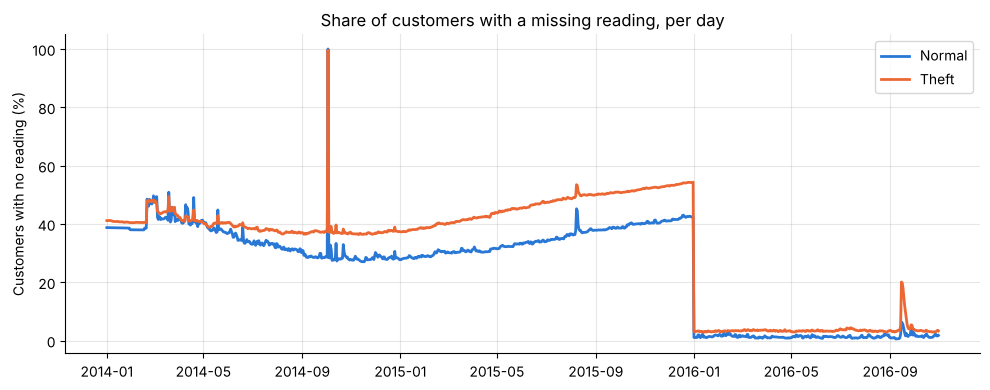

In [13]:
daily_missing_normal = is_missing.loc[is_normal].mean(axis=0) * 100
daily_missing_theft = is_missing.loc[is_theft].mean(axis=0) * 100

fig, ax = plt.subplots()
ax.plot(daily_missing_normal.index, daily_missing_normal.values, color=NORMAL_COLOR, linewidth=2, label="Normal")
ax.plot(daily_missing_theft.index, daily_missing_theft.values, color=THEFT_COLOR, linewidth=2, label="Theft")
ax.set_ylabel("Customers with no reading (%)")
ax.set_title("Share of customers with a missing reading, per day")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_missing_over_time.png", dpi=120)
plt.show()

### Missing *before the first reading* vs. scattered gaps
If a meter was installed (or connected to the system) late, every day before its first reading is
missing. We find each customer's first reading date and count how many of all missing cells fall
before it.

In [14]:
customers_with_any_reading = has_reading.any(axis=1)
first_reading_date = has_reading.loc[customers_with_any_reading].idxmax(axis=1)

# Number of missing columns before each customer's first reading
missing_before_first_reading = (consumption.columns.get_indexer(first_reading_date)).astype(int)
total_missing_cells_with_readings = is_missing.loc[customers_with_any_reading].to_numpy().sum()
share_leading = missing_before_first_reading.sum() / total_missing_cells_with_readings

print("Customers whose first reading is on the first day:",
      f"{(first_reading_date == first_date).mean():.1%}")
print("Share of missing cells that come BEFORE the customer's first reading:", f"{share_leading:.1%}")
print()
print("First reading date, by quarter (number of customers):")
print(first_reading_date.dt.to_period("Q").value_counts().sort_index().to_string())

Customers whose first reading is on the first day: 61.1%
Share of missing cells that come BEFORE the customer's first reading: 72.4%

First reading date, by quarter (number of customers):
2014Q1    27175
2014Q2     2889
2014Q3     2220
2014Q4      592
2015Q1       22
2015Q2        4
2015Q3        6
2016Q1     9322
2016Q2       68
2016Q3       68
2016Q4        1
Freq: Q-DEC


### Longest missing gap per customer
We compute, for every customer, the longest run of consecutive missing days, using only NumPy
array operations (no loops over customers):

1. For each day, write the position of the day if it has a reading, otherwise `-1`.
2. `np.maximum.accumulate` carries forward "the position of the most recent observed day".
3. Today's position minus that value is the length of the current missing run.
4. The maximum per row is the longest missing run.

(Counted in file columns; the one absent calendar day, 18 Sep 2016, is not counted.)

In [15]:
missing_array = is_missing.to_numpy()
day_position = np.arange(missing_array.shape[1])

last_observed_position = np.where(missing_array, -1, day_position)
last_observed_position = np.maximum.accumulate(last_observed_position, axis=1)
current_missing_run = day_position - last_observed_position

longest_missing_run = pd.Series(current_missing_run.max(axis=1), index=consumption.index)
missing_ratio = pd.Series(missing_array.mean(axis=1), index=consumption.index)

gap_summary = pd.DataFrame({
    "Normal": [
        missing_ratio[is_normal].median() * 100,
        longest_missing_run[is_normal].median(),
        (longest_missing_run[is_normal] > 30).mean() * 100,
        (longest_missing_run[is_normal] > 365).mean() * 100,
        (missing_ratio[is_normal] == 0).mean() * 100,
    ],
    "Theft": [
        missing_ratio[is_theft].median() * 100,
        longest_missing_run[is_theft].median(),
        (longest_missing_run[is_theft] > 30).mean() * 100,
        (longest_missing_run[is_theft] > 365).mean() * 100,
        (missing_ratio[is_theft] == 0).mean() * 100,
    ],
}, index=[
    "Median missing-reading ratio per customer (%)",
    "Median longest missing gap (days)",
    "Customers with a gap longer than 30 days (%)",
    "Customers with a gap longer than 365 days (%)",
    "Customers with no missing reading at all (%)",
]).round(1)
gap_summary

,Normal,Theft
Median missing-reading ratio per customer (%),9.3,21.4
Median longest missing gap (days),82.0,192.0
Customers with a gap longer than 30 days (%),54.1,68.7
Customers with a gap longer than 365 days (%),27.3,36.6
Customers with no missing reading at all (%),0.0,0.0


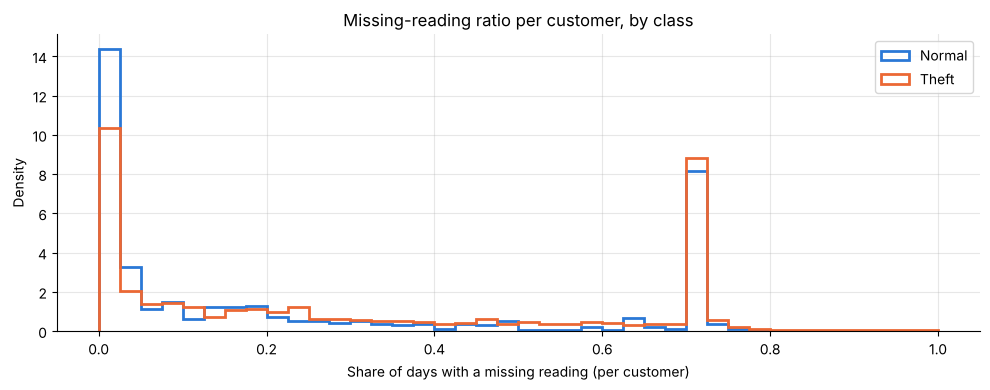

In [16]:
bins = np.linspace(0, 1, 41)
fig, ax = plt.subplots()
ax.hist(missing_ratio[is_normal], bins=bins, density=True, histtype="step", linewidth=2, color=NORMAL_COLOR, label="Normal")
ax.hist(missing_ratio[is_theft], bins=bins, density=True, histtype="step", linewidth=2, color=THEFT_COLOR, label="Theft")
ax.set_xlabel("Share of days with a missing reading (per customer)")
ax.set_ylabel("Density")
ax.set_title("Missing-reading ratio per customer, by class")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_missing_ratio_by_class.png", dpi=120)
plt.show()

**What we see.**
- **Overall:** 25.64% of readings are missing: 25.10% for normal customers and 31.47% for theft
  customers. This matches the report.
- **By year:** 35.29% (2014), 35.99% (2015) and 1.62% (2016). Theft customers have more gaps in
  every year, especially in 2015 (46.60% vs 35.00%).
- **Over time:** the daily plot shows the drop in missingness is not gradual. It happens as a
  **sudden step on 1 Jan 2016**. Before that, missingness among theft customers slowly *rises*
  during 2015.
- **Late starters:** 72.4% of all missing cells lie *before* a customer's first reading. Most
  missingness therefore means "this meter was not reporting yet", not random gaps. 61.1% of
  customers report from the first day, but 9,322 customers have their first reading in the first
  quarter of 2016, which means about two years with no data.
- **Per customer:** the median missing-reading ratio is 21.4% for theft vs 9.3% for normal, and the
  median longest gap is 192 vs 82 days.
- **No complete records:** 0.0% of customers have a fully complete record, because almost nobody
  has a reading on 3 Oct 2014 (see Section 6).

**Why it matters.**
- Missingness carries information about the label. This supports decision **D4**: the
  missing-reading ratio becomes a feature, computed *before* any imputation (D3).
- We do not know *why* theft customers have more gaps. It may be linked to how the labels were
  assigned. A model that uses it is learning "more gaps → more suspicious", which is acceptable
  for ranking inspection leads but must be stated honestly.
- For many customers, imputing the long gaps before their first reading means inventing up to two
  years of data. Notebook 02 has to choose and document a simple, leakage-safe way to handle this.

## 5. Zero consumption and extreme readings

### 5a. Zero readings
A reading of exactly 0 kWh can be genuine (an empty house) or suspicious (a bypassed meter).
We measure zeros **only among observed days** (missing days are not zeros).

In [17]:
is_zero = consumption == 0
observed_days = has_reading.sum(axis=1)
zero_days = is_zero.sum(axis=1)
positive_days = (consumption > 0).sum(axis=1)

# Zero-day ratio per customer (NaN for customers with no readings at all)
zero_ratio = zero_days / observed_days.replace(0, np.nan)

zero_summary = pd.DataFrame({
    "Normal": [
        zero_days[is_normal].sum() / observed_days[is_normal].sum() * 100,
        zero_ratio[is_normal].median() * 100,
        (zero_ratio[is_normal] > 0.5).mean() * 100,
        ((observed_days > 0) & (positive_days == 0))[is_normal].sum(),
    ],
    "Theft": [
        zero_days[is_theft].sum() / observed_days[is_theft].sum() * 100,
        zero_ratio[is_theft].median() * 100,
        (zero_ratio[is_theft] > 0.5).mean() * 100,
        ((observed_days > 0) & (positive_days == 0))[is_theft].sum(),
    ],
}, index=[
    "Zero readings among observed readings (%)",
    "Median zero-day ratio per customer (%)",
    "Customers with more than half of observed days at zero (%)",
    "Customers whose observed readings are ALL zero (count)",
]).round(2)
zero_summary

,Normal,Theft
Zero readings among observed readings (%),18.25,12.13
Median zero-day ratio per customer (%),0.74,0.40
Customers with more than half of observed days at zero (%),16.82,8.82
Customers whose observed readings are ALL zero (count),2076.00,33.00


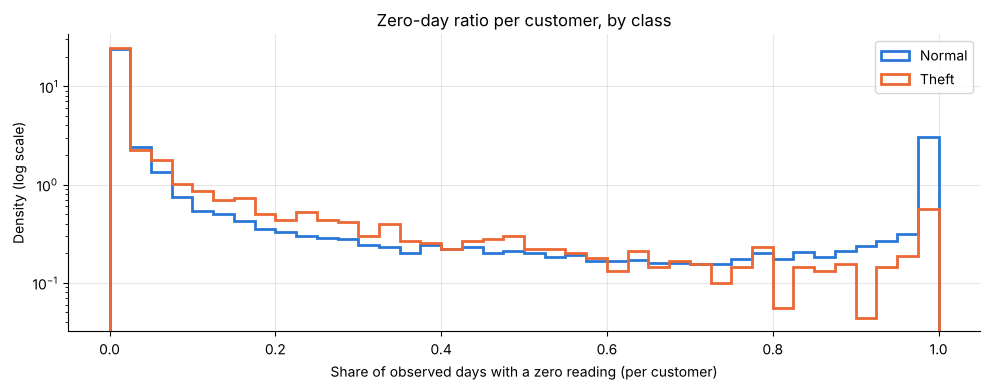

In [18]:
bins = np.linspace(0, 1, 41)
fig, ax = plt.subplots()
ax.hist(zero_ratio[is_normal].dropna(), bins=bins, density=True, histtype="step", linewidth=2, color=NORMAL_COLOR, label="Normal")
ax.hist(zero_ratio[is_theft].dropna(), bins=bins, density=True, histtype="step", linewidth=2, color=THEFT_COLOR, label="Theft")
ax.set_yscale("log")
ax.set_xlabel("Share of observed days with a zero reading (per customer)")
ax.set_ylabel("Density (log scale)")
ax.set_title("Zero-day ratio per customer, by class")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_zero_ratio_by_class.png", dpi=120)
plt.show()

**What we see.**
- Zero readings are common, and they are **more common for normal customers**: 18.25% of normal
  customers' observed readings are zero, against 12.13% for theft customers.
- 16.82% of normal customers (vs 8.82% of theft customers) read zero on more than half of their
  observed days.
- 2,076 normal customers and 33 theft customers read zero on *every* observed day. These are
  probably empty or inactive premises.

**Why it matters.** In this dataset, "many zero readings" is **not** a theft signal on its own.
The report's zero-based features (zero-day ratio, longest zero run) are still worth computing,
but the models will decide whether they help. We should not assume they do.

### 5b. Extreme readings
Our report mentions readings up to about 800,000 kWh in a single day, while a typical customer uses
a few kWh per day. We look at:
1. percentiles of all observed readings,
2. how many readings and customers exceed several fixed thresholds (and how many of those fall on
   the 3 Oct 2014 glitch day),
3. the ten largest readings, compared with that customer's own typical (median) day.

These are **whole-dataset** statistics for understanding only. Per decision D2, any capping
threshold will be derived from **training customers only** in Notebook 02.

In [19]:
all_values = consumption.to_numpy()
observed_values = all_values[~missing_array]

percentile_levels = [50, 90, 99, 99.9, 99.99, 100]
percentile_names = ["50th percentile (median)", "90th percentile", "99th percentile",
                    "99.9th percentile", "99.99th percentile", "Maximum"]
reading_percentiles = pd.Series(np.percentile(observed_values, percentile_levels), index=percentile_names)
print("Observed readings:", f"{observed_values.size:,}")
print("Negative readings:", int((observed_values < 0).sum()))
print()
print(reading_percentiles.round(2).to_string())

Observed readings: 32,579,120
Negative readings: 0

50th percentile (median)         4.59
90th percentile                 17.31
99th percentile                 69.79
99.9th percentile              371.86
99.99th percentile            1954.05
Maximum                     800003.32


In [20]:
is_glitch_column = consumption.columns == GLITCH_DATE

threshold_rows = []
for threshold in [100, 1_000, 10_000, 100_000]:
    above = all_values > threshold          # NaN compares as False
    customers_above = above.any(axis=1)
    threshold_rows.append({
        "Threshold (kWh/day)": f"> {threshold:,}",
        "Readings above": int(above.sum()),
        "...of which on 3 Oct 2014": int(above[:, is_glitch_column].sum()),
        "Customers affected": int(customers_above.sum()),
        "Normal customers affected": int(customers_above[is_normal].sum()),
        "Theft customers affected": int(customers_above[is_theft].sum()),
    })
extreme_table = pd.DataFrame(threshold_rows).set_index("Threshold (kWh/day)")
extreme_table

,Readings above,...of which on 3 Oct 2014,Customers affected,Normal customers affected,Theft customers affected
Threshold (kWh/day),,,,,
> 100,201145,9,1895,1350,545
"> 1,000",8594,3,406,359,47
"> 10,000",260,0,43,37,6
"> 100,000",6,0,6,4,2


In [21]:
# Find the 10 largest readings in the whole table (missing values treated as -infinity)
flat_values = np.where(missing_array, -np.inf, all_values).ravel()
top_positions = np.argpartition(flat_values, -10)[-10:]
top_positions = top_positions[np.argsort(flat_values[top_positions])[::-1]]
top_rows, top_columns = np.unravel_index(top_positions, all_values.shape)

customer_median = consumption.median(axis=1)

top_readings = pd.DataFrame({
    "Customer": consumption.index[top_rows],
    "Date": consumption.columns[top_columns].date,
    "Label (1 = theft)": labels.iloc[top_rows].to_numpy(),
    "Reading (kWh)": all_values[top_rows, top_columns],
    "Customer's median day (kWh)": customer_median.iloc[top_rows].to_numpy(),
})
top_readings["Customer's 2nd-largest reading (kWh)"] = np.sort(
    np.where(missing_array[top_rows], -np.inf, all_values[top_rows]), axis=1)[:, -2]
top_readings.round(2)

,Customer,Date,Label (1 = theft),Reading (kWh),Customer's median day (kWh),Customer's 2nd-largest reading (kWh)
0,C096AE4A4620C4B59792DAEE3AA5042E,2014-10-10,0,800003.32,3.55,13.05
1,7007AA54F17706C7761A8E5FBFA5C48B,2014-06-29,0,653502.79,3.41,9.59
2,107EF5035C79EADCF8C8E023120F01ED,2014-07-11,0,640000.00,0.00,0.00
3,CA2ACC65776CD4FE6F9B5186B361FDE2,2014-07-10,0,554535.44,0.00,0.00
4,D849516559C90DFA933D8195CF1DA5DA,2014-01-25,1,514991.78,2.83,462.35
5,130F129A06DD299839553DD35D14B35A,2014-05-07,1,466714.40,2099.80,4028.40
6,D5B288D1080FBA887EDF01D0AF634CF0,2014-01-13,1,92713.90,193.10,819.43
7,941C5045E4C2B562647E478EB1C9B21B,2014-05-07,1,57062.68,81.94,55964.07
8,941C5045E4C2B562647E478EB1C9B21B,2014-04-15,1,55964.07,81.94,55964.07
9,149BC60A18CFC75066DAE75308DFE24F,2014-03-18,0,53532.00,0.00,16.05


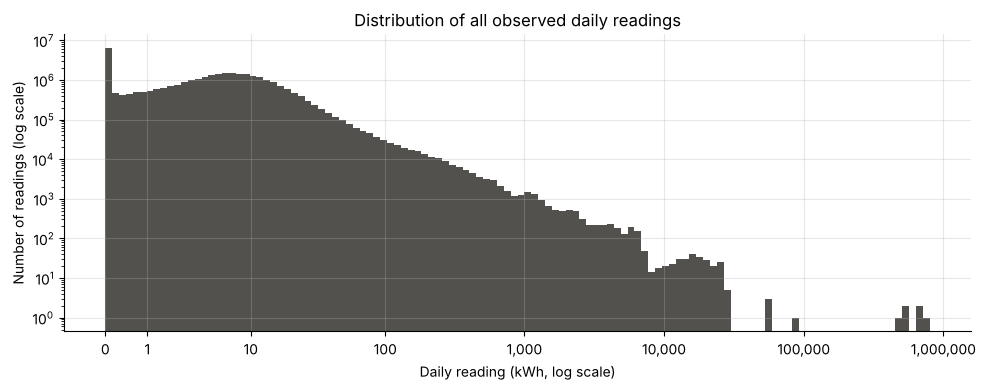

In [22]:
fig, ax = plt.subplots()
ax.hist(np.log10(observed_values + 1), bins=120, color=NEUTRAL_COLOR)
ax.set_yscale("log")
tick_values = np.array([0, 1, 10, 100, 1_000, 10_000, 100_000, 1_000_000])
ax.set_xticks(np.log10(tick_values + 1))
ax.set_xticklabels([f"{value:,}" for value in tick_values])
ax.set_xlabel("Daily reading (kWh, log scale)")
ax.set_ylabel("Number of readings (log scale)")
ax.set_title("Distribution of all observed daily readings")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_reading_distribution.png", dpi=120)
plt.show()

**What we see.**
- The distribution is extremely right-skewed. The median reading is 4.59 kWh and the 99th
  percentile is 69.79 kWh, but the 99.99th percentile is 1,954.05 kWh and the maximum is
  800,003.32 kWh.
- 8,594 readings are above 1,000 kWh (across 406 customers), 260 are above 10,000 kWh (43
  customers) and 6 are above 100,000 kWh.
- Most of the largest readings are **isolated spikes**. For example, the 800,003.32 kWh reading
  belongs to a customer whose median day is 3.55 kWh and whose second-largest reading is 13.05 kWh.
  That is physically implausible for a household, so it is almost certainly a recording error.
- **Not every large value is an error.** One theft customer in the top-10 table has a median day of
  2,099.80 kWh, which looks like a genuinely large (perhaps commercial) consumer.
- The extremes are **not** caused by the 3 Oct 2014 glitch: only 3 of the readings above
  1,000 kWh fall on that day.

**Is capping justified? Yes, with care (decision D2).** Isolated values hundreds of thousands of
times larger than a customer's normal day would dominate averages, standard deviations and
scaling. Our recommendation for Notebook 02:
- Compute one **very high percentile of the training customers' readings** (for example the
  99.99th) and cap every reading above it, in all three splits.
- The whole-dataset value printed above (1,954.05 kWh) is for orientation only. The real threshold
  must come from training customers.
- A very high percentile changes only the most extreme readings and leaves large but genuine
  consumers mostly intact.
- A `log1p` transform before scaling then reduces the remaining skew for the deep learning models.

## 6. The 3 October 2014 glitch
Our report found that the median reading jumps from about 4.5 kWh to 144 kWh on 3 Oct 2014 and
described it as a system-wide glitch. A median depends on **how many** values it is computed from,
so we look at the median **and** at how many customers actually have a reading on each day.

In [23]:
daily_median_all = consumption.median(axis=0)
daily_median_normal = consumption.loc[is_normal].median(axis=0)
daily_median_theft = consumption.loc[is_theft].median(axis=0)

glitch_window = pd.DataFrame({
    "Median, all (kWh)": daily_median_all,
    "Median, normal (kWh)": daily_median_normal,
    "Median, theft (kWh)": daily_median_theft,
    "Customers with a reading (%)": has_reading.mean(axis=0) * 100,
}).loc["2014-09-29":"2014-10-07"].round(2)
glitch_window.index = glitch_window.index.date
glitch_window

,"Median, all (kWh)","Median, normal (kWh)","Median, theft (kWh)",Customers with a reading (%)
2014-09-29,4.94,4.83,6.62,70.74
2014-09-30,4.89,4.80,6.56,70.43
2014-10-01,4.48,4.37,5.89,70.52
2014-10-02,4.48,4.38,5.97,70.70
2014-10-03,144.00,NaN,144.00,0.04
2014-10-04,4.07,3.98,5.14,70.67
2014-10-05,3.95,3.86,5.22,70.94
2014-10-06,3.97,3.88,5.08,66.70
2014-10-07,4.02,3.95,5.01,68.18


In [24]:
glitch_readings = consumption[GLITCH_DATE]
has_glitch_reading = glitch_readings.notna()
daily_coverage_pct = has_reading.mean(axis=0) * 100

print("Customers with a reading on 3 Oct 2014:", int(has_glitch_reading.sum()), "out of", f"{n_customers:,}")
print("Labels of those customers (label -> count):", labels[has_glitch_reading].value_counts().to_dict())
print("Days (other than 3 Oct 2014) whose median across customers is above 50 kWh:",
      int((daily_median_all.drop(GLITCH_DATE) > 50).sum()))
print()
print("The 3 days with the lowest share of customers reporting (%):")
print(daily_coverage_pct.sort_values().head(3).round(2).to_string())

Customers with a reading on 3 Oct 2014: 15 out of 42,372
Labels of those customers (label -> count): {1: 15}
Days (other than 3 Oct 2014) whose median across customers is above 50 kWh: 0

The 3 days with the lowest share of customers reporting (%):
2014-10-03     0.04
2014-03-19    49.25
2014-02-28    50.47


The customers who **do** have a reading on 3 Oct 2014, with their label and their own typical day:

In [25]:
glitch_day_readers = pd.DataFrame({
    "Reading on 3 Oct 2014 (kWh)": glitch_readings[has_glitch_reading],
    "Customer's median day (kWh)": customer_median[has_glitch_reading],
    "Label (1 = theft)": labels[has_glitch_reading],
})
glitch_day_readers.sort_values("Reading on 3 Oct 2014 (kWh)")

,Reading on 3 Oct 2014 (kWh),Customer's median day (kWh),Label (1 = theft)
CONS_NO,,,
812B5E1975D50353789BD3BC9A16A035,15.30,0.0000,1
5E888DF9ECCCC1399B4D9AB0FCEFE111,16.00,7.2000,1
26E3A942DCF86C77117F931AEA73BBD1,30.39,6.4408,1
D0391FAF3CE4A14E79068C51D911DC39,36.00,48.0000,1
8E6CDBF84C48D0708AC070DE0A86E4F0,64.60,1.3000,1
6568B41CD5113166E7FE87B43A704A87,97.20,0.0000,1
837D54985C93D7902649F9AFDCD0B484,138.00,1425.0000,1
E3C0FAA27DE808E5130D83EA58B7D754,144.00,102.0000,1
8DF0CD96150F92A6F6F19DD668361E6C,156.80,157.6000,1


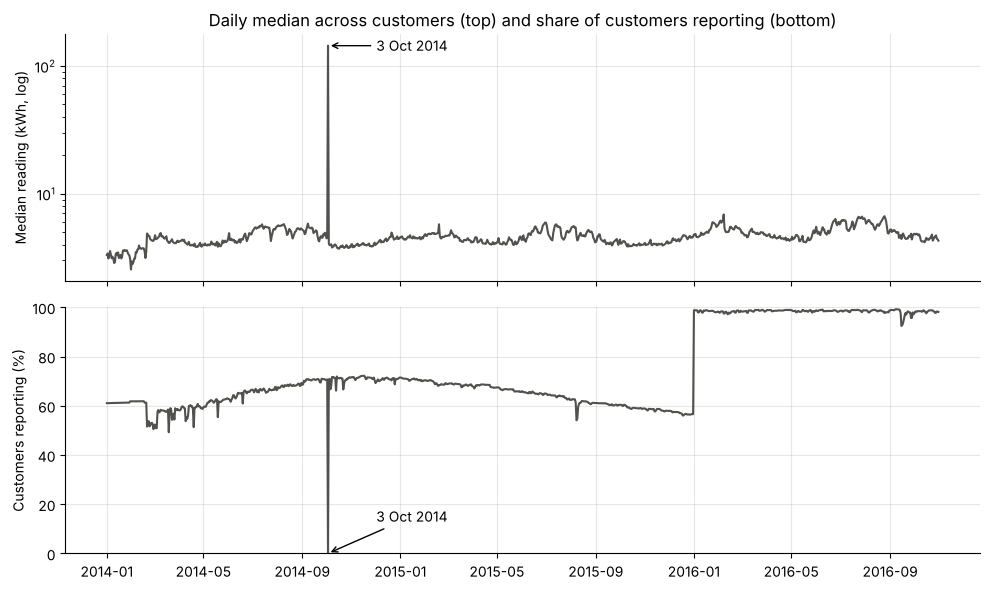

In [26]:
# Two separate panels (one y-axis each): the daily median, and how many customers it is based on
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(daily_median_all.index, daily_median_all.values, color=NEUTRAL_COLOR, linewidth=1.5)
axes[0].set_yscale("log")
axes[0].set_ylabel("Median reading (kWh, log)")
axes[0].set_title("Daily median across customers (top) and share of customers reporting (bottom)")
axes[0].annotate("3 Oct 2014", xy=(GLITCH_DATE, daily_median_all[GLITCH_DATE]),
                 xytext=(GLITCH_DATE + pd.Timedelta(days=60), daily_median_all[GLITCH_DATE]),
                 arrowprops={"arrowstyle": "->"}, va="center")

axes[1].plot(daily_coverage_pct.index, daily_coverage_pct.values, color=NEUTRAL_COLOR, linewidth=1.5)
axes[1].set_ylim(0, 100)
axes[1].set_ylabel("Customers reporting (%)")
axes[1].annotate("3 Oct 2014", xy=(GLITCH_DATE, daily_coverage_pct[GLITCH_DATE]),
                 xytext=(GLITCH_DATE + pd.Timedelta(days=60), 15),
                 arrowprops={"arrowstyle": "->"}, va="center")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_glitch_day.png", dpi=120)
plt.show()

**What we see — and a correction to our report.**
- The numbers in the report are right: the median jumps from 4.48 kWh on 2 Oct 2014 to 144.00 kWh on
  3 Oct 2014. No other day has a median above 50 kWh.
- But **only 15 of 42,372 customers (0.04%) have any reading on 3 Oct 2014**, compared with about 70%
  on the days around it. It is by far the emptiest day; the next lowest day still has about 49% of
  customers reporting.
- The "144 kWh" is the median of just 15 values. It is **not** a jump in everybody's consumption.
  Many of these 15 are large consumers whose reading that day is close to their own typical day
  (for example 156.80 kWh against a median day of 157.60 kWh). The high median comes from *which*
  customers reported, not mainly from wrong values.
- **All 15 of these customers are labelled theft.** So "has a reading on 3 Oct 2014" would identify
  them perfectly. This is a data artefact, and a model could exploit it as a label leak.

So the 3 Oct 2014 anomaly is best described as a **nearly empty day whose few readings all belong to
theft customers**, not as a system-wide spike in readings. Our report's description should be read
with this correction.

**For Notebook 02.** The planned treatment, setting 3 Oct 2014 to missing for **every** customer, is
still right and is now more important. It must be done **before** any feature is computed, including
the missing-reading ratio, so that no feature can tell who had a reading that day.

## 7. The customers with no readings at all
During dataset verification we found a few customers whose every daily value is missing. We list them
here. We do **not** remove them in this notebook.

In [27]:
is_empty_customer = ~customers_with_any_reading

empty_customers = pd.DataFrame({
    "Label (1 = theft)": labels[is_empty_customer],
    "Observed days": observed_days[is_empty_customer],
    "Row position in raw file": np.flatnonzero(is_empty_customer.to_numpy()),
})
print("Number of customers with no readings:", int(is_empty_customer.sum()))
empty_customers

Number of customers with no readings: 5


,Label (1 = theft),Observed days,Row position in raw file
CONS_NO,,,
58C5C2F9D81EA5DC8421CACB0C73E495,1,0,419
6BE983A5063B5DF9225ADD95AD3F241B,1,0,686
2B981D4283253BA362DB2915358B88BF,1,0,3028
D176EB392233366F6F38E46AA592154E,0,0,37830
A63E94C418356023D70BE00B7FE2C4EE,0,0,41998


**What we see.** Five customers (3 labelled theft, 2 labelled normal) have no reading on any of the
1,034 days. Section 8 shows that they also form one "identical history" group, and that group has
conflicting labels.

**Recommendation for Notebook 02.** Remove these 5 customers **before** the split. They contain no
consumption data, so no model can learn from them or score them meaningfully. Keeping them would
only add rows that every model must guess.

## 8. Identical consumption records and contradictory labels
Two different customers should almost never have exactly the same 1,034 daily readings. We look for
customers whose full reading history (including where the gaps are) is identical to at least one other
customer's history.

To group identical histories we give each customer a **fingerprint**: `pd.util.hash_pandas_object`
turns a whole row into one number, and identical rows get identical numbers. Missing values are first
replaced by `-1` so that "missing on the same days" also counts as identical. This is done on a
temporary copy for comparison only.

In [28]:
is_identical_record = consumption.duplicated(keep=False)   # True for every copy, including the first
row_fingerprint = pd.util.hash_pandas_object(consumption.fillna(-1), index=False)
row_fingerprint.index = consumption.index

identical_records = pd.DataFrame({
    "fingerprint": row_fingerprint[is_identical_record],
    "label": labels[is_identical_record],
    "observed_days": observed_days[is_identical_record],
    "positive_days": positive_days[is_identical_record],
})

group_summary = identical_records.groupby("fingerprint").agg(
    group_size=("label", "size"),
    theft_count=("label", "sum"),
    observed_days=("observed_days", "first"),
    positive_days=("positive_days", "first"),
)
group_summary["normal_count"] = group_summary["group_size"] - group_summary["theft_count"]
group_summary["contradictory"] = (group_summary["theft_count"] > 0) & (group_summary["normal_count"] > 0)
group_summary["content"] = np.select(
    [group_summary["observed_days"] == 0, group_summary["positive_days"] == 0],
    ["all readings missing", "only zeros (and gaps)"],
    default="has non-zero readings",
)

print("Customers that share their exact history with another customer:", int(is_identical_record.sum()))
print("Number of distinct identical-history groups:", len(group_summary))
print("Check: distinct histories among them =", len(consumption[is_identical_record].drop_duplicates()))

Customers that share their exact history with another customer: 1014
Number of distinct identical-history groups: 136
Check: distinct histories among them = 136


In [29]:
content_table = group_summary.groupby("content").agg(
    groups=("group_size", "size"),
    customers=("group_size", "sum"),
    theft_customers=("theft_count", "sum"),
    normal_customers=("normal_count", "sum"),
    contradictory_groups=("contradictory", "sum"),
)
content_table

,groups,customers,theft_customers,normal_customers,contradictory_groups
content,,,,,
all readings missing,1,5,3,2,1
has non-zero readings,2,4,0,4,0
only zeros (and gaps),133,1005,15,990,4


In [30]:
print("Group sizes (how many customers share one history -> number of groups):")
print(group_summary["group_size"].value_counts().sort_index().to_string())

Group sizes (how many customers share one history -> number of groups):
group_size
2      74
3      24
4       9
5       8
6       4
7       1
8       3
10      3
11      1
14      1
17      1
18      1
23      1
28      1
31      1
33      1
60      1
398     1


### Groups with contradictory labels
A group is contradictory when identical histories carry **both** labels (some copies say theft,
others say normal). A model cannot possibly get all of them right.

In [31]:
contradictory_groups = group_summary[group_summary["contradictory"]]
contradictory_display = contradictory_groups[["group_size", "theft_count", "normal_count",
                                              "observed_days", "positive_days", "content"]].reset_index(drop=True)
contradictory_display.index = [f"Group {number + 1}" for number in range(len(contradictory_display))]
contradictory_display

,group_size,theft_count,normal_count,observed_days,positive_days,content
Group 1,5,3,2,0,0,all readings missing
Group 2,398,11,387,304,0,only zeros (and gaps)
Group 3,3,1,2,32,0,only zeros (and gaps)
Group 4,31,1,30,588,0,only zeros (and gaps)
Group 5,60,2,58,1033,0,only zeros (and gaps)


### What would remain under the cleaning we recommend (not applied here)
To support the decision in Notebook 02, we *count* (without removing anything) what would remain if we:
1. dropped customers with no readings,
2. dropped every customer in a contradictory-label group,
3. kept only the first copy of every other identical-history group.

In [32]:
contradictory_fingerprints = contradictory_groups.index
in_contradictory_group = row_fingerprint.isin(contradictory_fingerprints) & is_identical_record
is_first_copy = ~consumption.duplicated(keep="first")

would_keep = customers_with_any_reading & ~in_contradictory_group & is_first_copy

what_if = pd.DataFrame({
    "Now": [len(labels), int(is_theft.sum()), int(is_normal.sum())],
    "After recommended cleaning": [int(would_keep.sum()), int(labels[would_keep].sum()),
                                   int((labels[would_keep] == 0).sum())],
}, index=["Customers", "Theft", "Normal"])
what_if["Removed"] = what_if["Now"] - what_if["After recommended cleaning"]
what_if

,Now,After recommended cleaning,Removed
Customers,42372,41489,883
Theft,3615,3597,18
Normal,38757,37892,865


**What we see.**
- 1,014 customers share their exact history (every reading and every gap) with at least one other
  customer. They form 136 groups, and the cross-check confirms 136 distinct histories.
- **Almost all of these are "empty" histories:**
  - 1,005 customers (133 groups) have *only zeros and gaps*;
  - 5 are the customers with no readings at all;
  - only 2 groups (4 normal customers) contain non-zero readings.
- The largest group has **398 customers** with the same 304 observed days, all zero, and gaps on
  exactly the same days.
- **5 groups have contradictory labels**: the 398-customer group (11 theft, 387 normal), the
  5 empty customers (3 theft, 2 normal), and three smaller all-zero groups.

**Why it matters.**
1. **Leakage.** If copies of the same history land in both the training and the test set, the model
   has effectively seen the test input during training, and test results look better than they are.
2. **Label noise.** Identical inputs with different labels cannot all be predicted correctly. They
   add noise without information.
3. All-zero histories with identical gap patterns look like inactive meters, not distinct
   households.

**Recommendation for Notebook 02 (counted above, not applied here):**
- Drop the empty customers.
- Drop every customer in a contradictory-label group.
- Keep only one copy of every other identical-history group.
- Do all of this **before** the split.

This would leave 41,489 customers (3,597 theft, 37,892 normal), removing 883 rows (18 theft,
865 normal). The final decision is the team's.

## 9. Normal vs. theft customers

### 9a. Typical daily consumption over time
For each day we take the median reading of all normal customers and of all theft customers, then
smooth with a 7-day rolling mean to make the trend readable. The glitch day is hidden **in this plot
only** so that it does not hide the trend.

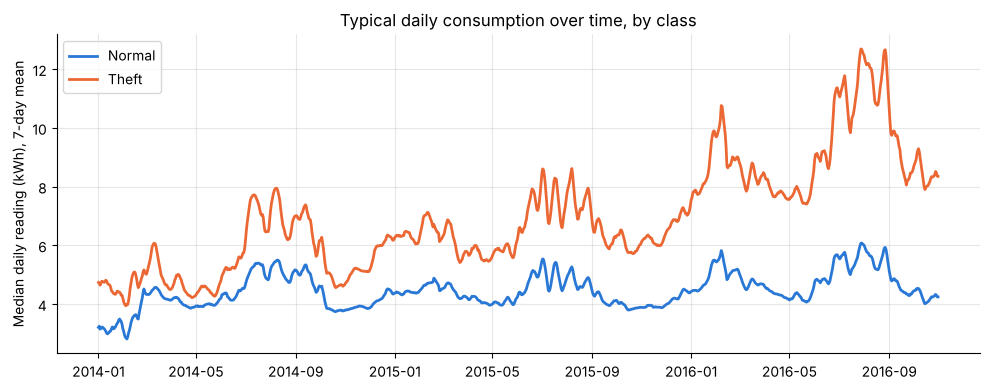

In [33]:
daily_median_by_class = pd.DataFrame({"Normal": daily_median_normal, "Theft": daily_median_theft})
daily_median_by_class.loc[GLITCH_DATE] = np.nan          # plot only: hide the glitch day
smoothed_by_class = daily_median_by_class.rolling(7, min_periods=1).mean()

fig, ax = plt.subplots()
ax.plot(smoothed_by_class.index, smoothed_by_class["Normal"], color=NORMAL_COLOR, linewidth=2, label="Normal")
ax.plot(smoothed_by_class.index, smoothed_by_class["Theft"], color=THEFT_COLOR, linewidth=2, label="Theft")
ax.set_ylabel("Median daily reading (kWh), 7-day mean")
ax.set_title("Typical daily consumption over time, by class")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_daily_median_by_class.png", dpi=120)
plt.show()

### 9b. Example customers
Three randomly chosen normal customers and three randomly chosen theft customers (fixed random seed),
picked among customers with readings on at least 90% of days so that the lines are readable. The glitch
day is left out of these plots.

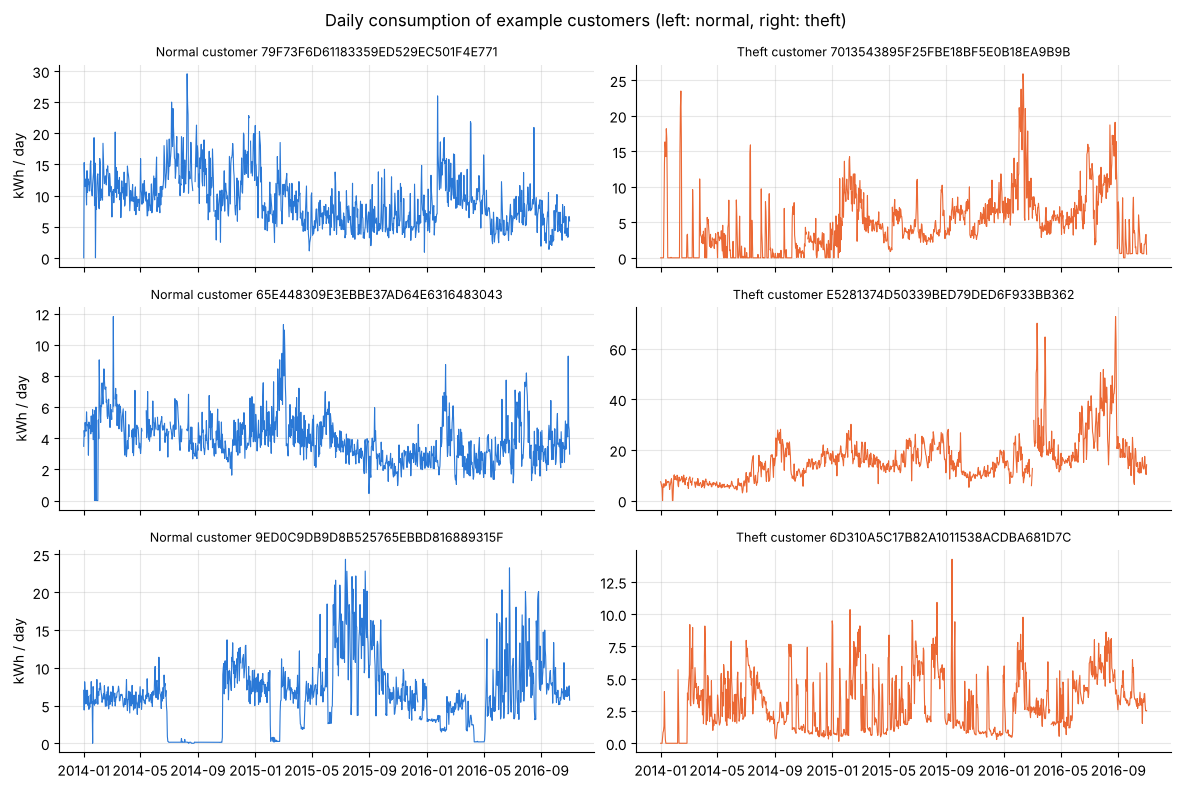

In [34]:
random_generator = np.random.default_rng(RANDOM_STATE)
well_observed = (observed_days / consumption.shape[1] >= 0.9).to_numpy()

normal_examples = random_generator.choice(consumption.index[is_normal & well_observed], size=3, replace=False)
theft_examples = random_generator.choice(consumption.index[is_theft & well_observed], size=3, replace=False)

fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True)
for row in range(3):
    normal_series = consumption.loc[normal_examples[row]].drop(GLITCH_DATE)
    theft_series = consumption.loc[theft_examples[row]].drop(GLITCH_DATE)
    axes[row, 0].plot(normal_series.index, normal_series.values, color=NORMAL_COLOR, linewidth=0.8)
    axes[row, 0].set_title(f"Normal customer {normal_examples[row]}", fontsize=9)
    axes[row, 1].plot(theft_series.index, theft_series.values, color=THEFT_COLOR, linewidth=0.8)
    axes[row, 1].set_title(f"Theft customer {theft_examples[row]}", fontsize=9)
    axes[row, 0].set_ylabel("kWh / day")
fig.suptitle("Daily consumption of example customers (left: normal, right: theft)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_example_customers.png", dpi=120)
plt.show()

### 9c. Average consumption per customer
Each customer's average daily reading (over observed days), compared between the classes.

In [35]:
customer_mean = consumption.mean(axis=1)    # NaN for customers with no readings

mean_summary = pd.DataFrame({
    "Normal": customer_mean[is_normal].describe(percentiles=[0.25, 0.5, 0.75]),
    "Theft": customer_mean[is_theft].describe(percentiles=[0.25, 0.5, 0.75]),
}).round(2)
mean_summary

,Normal,Theft
count,38755.00,3612.00
mean,7.95,31.35
std,19.73,272.55
min,0.00,0.00
25%,1.77,4.49
50%,5.47,8.80
75%,9.85,16.54
max,1480.33,13601.10


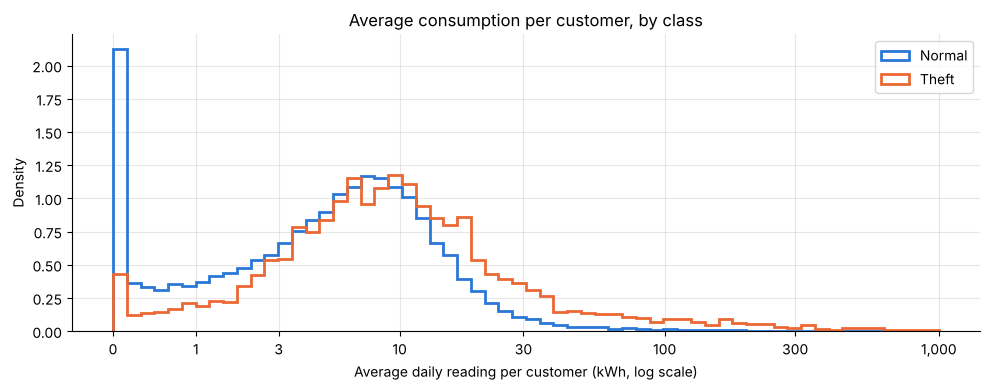

In [36]:
bins = np.linspace(0, 3, 61)
fig, ax = plt.subplots()
ax.hist(np.log10(customer_mean[is_normal].dropna() + 1), bins=bins, density=True, histtype="step",
        linewidth=2, color=NORMAL_COLOR, label="Normal")
ax.hist(np.log10(customer_mean[is_theft].dropna() + 1), bins=bins, density=True, histtype="step",
        linewidth=2, color=THEFT_COLOR, label="Theft")
tick_values = np.array([0, 1, 3, 10, 30, 100, 300, 1000])
ax.set_xticks(np.log10(tick_values + 1))
ax.set_xticklabels([f"{value:,}" for value in tick_values])
ax.set_xlabel("Average daily reading per customer (kWh, log scale)")
ax.set_ylabel("Density")
ax.set_title("Average consumption per customer, by class")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_customer_mean_by_class.png", dpi=120)
plt.show()

**What we see.**
- **Higher consumption.** Theft-labelled customers have a *higher* typical daily consumption than
  normal customers on almost every day. The gap widens over time, especially in 2016.
- **Per customer.** The median average is 8.80 kWh/day for theft vs 5.47 kWh/day for normal.
- **Heavy tail.** The mean of the theft group (31.35) is far above its median, because a few
  theft customers consume very large amounts.
- **No single visual pattern.** The example customers show that both classes contain smooth,
  spiky, gappy and zero-heavy histories.

**Why it matters.**
- Many people expect "theft" to mean "low recorded consumption". In this dataset the theft label goes
  together with **higher** recorded consumption on average. We do not know how the labels were
  assigned, so we report this without explaining it away.
- Because no single visual pattern separates the classes, we need models. That is the motivation
  for the rest of the project.

## 10. Consumption trends and distributions

### 10a. Year-by-year average consumption
For every customer we compute the average daily reading in each year (observed days only), then take
the median across customers in each class. The glitch day is excluded.

In [37]:
not_glitch = consumption.columns != GLITCH_DATE

yearly_mean = pd.DataFrame(index=consumption.index)
for year in [2014, 2015, 2016]:
    year_columns = (consumption.columns.year == year) & not_glitch
    yearly_mean[year] = consumption.loc[:, year_columns].mean(axis=1)

yearly_trend = pd.DataFrame({
    "Normal: median of yearly averages (kWh/day)": yearly_mean[is_normal].median(),
    "Theft: median of yearly averages (kWh/day)": yearly_mean[is_theft].median(),
}).round(2)
yearly_trend.index.name = "Year"
yearly_trend

,Normal: median of yearly averages (kWh/day),Theft: median of yearly averages (kWh/day)
Year,,
2014,5.00,6.49
2015,4.98,7.51
2016,5.65,10.17


### 10b. Is there a weekly cycle?
Our report says that the weekly cycle is weak. To check this, for each customer we divide their average
reading on each weekday by their overall average (1.0 = a normal day for that customer). We then take the
median across customers in each class. The glitch day (a Friday) is excluded.

In [38]:
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
customer_mean_no_glitch = consumption.loc[:, not_glitch].mean(axis=1)

weekday_relative = pd.DataFrame(index=consumption.index)
for day_number in range(7):
    weekday_columns = (consumption.columns.day_of_week == day_number) & not_glitch
    weekday_relative[weekday_names[day_number]] = (
        consumption.loc[:, weekday_columns].mean(axis=1) / customer_mean_no_glitch.replace(0, np.nan)
    )

weekday_profile = pd.DataFrame({
    "Normal": weekday_relative[is_normal].median(),
    "Theft": weekday_relative[is_theft].median(),
}).round(3)
weekday_profile.T

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
Normal,0.987,0.990,0.996,0.997,0.997,1.008,1.011
Theft,0.985,0.989,0.995,0.998,0.998,1.012,1.013


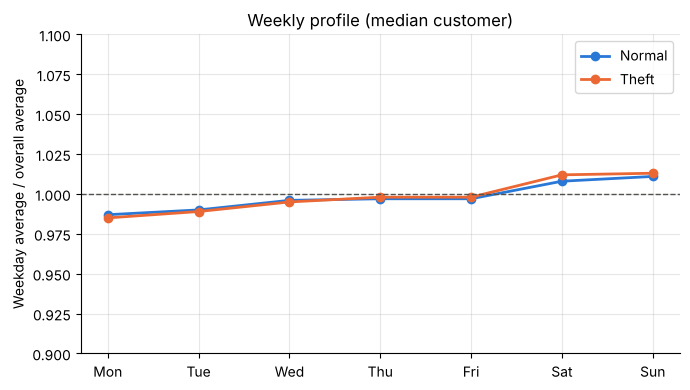

In [39]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(weekday_names, weekday_profile["Normal"], color=NORMAL_COLOR, marker="o", linewidth=2, label="Normal")
ax.plot(weekday_names, weekday_profile["Theft"], color=THEFT_COLOR, marker="o", linewidth=2, label="Theft")
ax.axhline(1.0, color=NEUTRAL_COLOR, linewidth=1, linestyle="--")
ax.set_ylim(0.9, 1.1)
ax.set_ylabel("Weekday average / overall average")
ax.set_title("Weekly profile (median customer)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_weekday_profile.png", dpi=120)
plt.show()

**What we see.**
- **Year by year:** the median normal customer's average stays almost flat (5.00, 4.98 and 5.65
  kWh/day in 2014, 2015 and 2016). The median theft customer's average rises steadily (6.49 → 7.51
  → 10.17 kWh/day).
- **Weekly cycle:** for both classes, every weekday is within about ±1.5% of the customer's overall
  average, with weekends very slightly higher. The two classes have almost identical weekly
  profiles.

**Why it matters.**
- This confirms our report: the weekly cycle is weak, and theft does **not** visibly "break a weekly
  rhythm". We will not claim that it does.
- The yearly change differs between the classes. This supports the report's feature "change from
  each customer's own baseline" (Notebook 03).

## 11. Exploratory baseline: average consumption as a theft score

Our report states that **average consumption alone** separates theft from normal customers with a
ROC-AUC of about 0.66. We reproduce this here: each customer's score is simply their average daily
reading, and we measure how well that score ranks theft customers above normal ones.

> **Important — this is NOT a model evaluation.**
> - It is computed on the **whole dataset**, not on held-out test customers.
> - Nothing is trained, so there is nothing to overfit, but it is still only an exploratory statistic.
> - The 5 customers with no readings get a score of 0 here.
> - The official baseline floor will be recomputed on the **test split** in Notebook 06, and every
>   model must clearly beat it there.

ROC-AUC = 0.5 means random ranking; 1.0 means every theft customer is ranked above every normal one.

In [40]:
baseline_score = customer_mean.fillna(0)
baseline_auc = roc_auc_score(labels, baseline_score)

print(f"Exploratory ROC-AUC of average consumption (whole dataset): {baseline_auc:.4f}")
print("Higher average consumption is associated with the theft label" if baseline_auc > 0.5
      else "Lower average consumption is associated with the theft label")

Exploratory ROC-AUC of average consumption (whole dataset): 0.6566
Higher average consumption is associated with the theft label


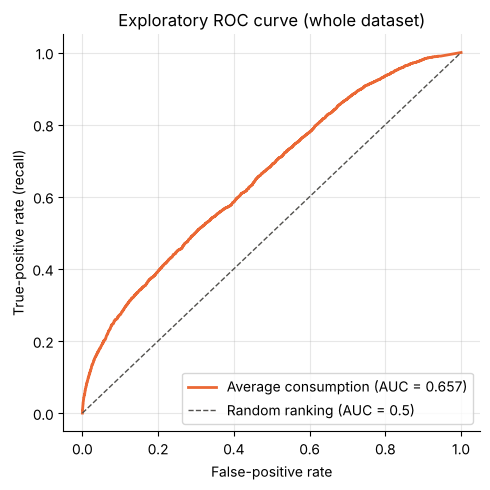

In [41]:
false_positive_rate, true_positive_rate, _ = roc_curve(labels, baseline_score)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(false_positive_rate, true_positive_rate, color=THEFT_COLOR, linewidth=2,
        label=f"Average consumption (AUC = {baseline_auc:.3f})")
ax.plot([0, 1], [0, 1], color=NEUTRAL_COLOR, linestyle="--", linewidth=1, label="Random ranking (AUC = 0.5)")
ax.set_xlabel("False-positive rate")
ax.set_ylabel("True-positive rate (recall)")
ax.set_title("Exploratory ROC curve (whole dataset)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_baseline_roc_exploratory.png", dpi=120)
plt.show()

**What we see.**
- Using only each customer's average daily reading as a score gives an exploratory ROC-AUC of
  **0.6566** on the whole dataset. This reproduces the report's "about 0.66".
- Higher averages are associated with the theft label, which agrees with Section 9.

**How to read it.** This is a **floor**, not a result: a score that needs no training already ranks
theft above normal about two-thirds of the time. In Notebook 06 we recompute this baseline on the
held-out **test** customers only. Every model must clearly beat that test-set value to justify its
complexity.

## 12. Summary of findings
The table below is built from variables computed above, so every number is traceable to this notebook.

In [42]:
summary = pd.Series({
    "Customers": f"{n_customers:,}",
    "Theft / normal": f"{n_theft:,} / {n_normal:,} ({theft_share:.2%} theft)",
    "Daily columns": f"{consumption.shape[1]:,} ({first_date.date()} to {last_date.date()})",
    "Calendar days with no column": ", ".join(str(day.date()) for day in dates_not_in_file),
    "Missing readings (all / normal / theft)":
        f"{overall_missing_pct:.2f}% / {normal_missing_pct:.2f}% / {theft_missing_pct:.2f}%",
    "Missing cells before the first reading": f"{share_leading:.1%}",
    "3 Oct 2014: median / customers reporting":
        f"{daily_median_all[GLITCH_DATE]:.2f} kWh / {int(has_glitch_reading.sum())} customers "
        f"(labels: {labels[has_glitch_reading].value_counts().to_dict()})",
    "Zero share of observed readings (normal / theft)":
        f"{zero_summary.iloc[0, 0]:.2f}% / {zero_summary.iloc[0, 1]:.2f}%",
    "Median of per-customer average (normal / theft)":
        f"{customer_mean[is_normal].median():.2f} / {customer_mean[is_theft].median():.2f} kWh/day",
    "Largest reading": f"{observed_values.max():,.2f} kWh",
    "Customers with no readings": f"{int(is_empty_customer.sum())}",
    "Customers sharing an identical history": f"{int(is_identical_record.sum()):,} in {len(group_summary)} groups",
    "Contradictory-label groups": f"{len(contradictory_groups)}",
    "Exploratory ROC-AUC of average consumption": f"{baseline_auc:.4f}",
}, name="Value")
summary.to_frame()

,Value
Customers,"42,372"
Theft / normal,"3,615 / 38,757 (8.53% theft)"
Daily columns,"1,034 (2014-01-01 to 2016-10-31)"
Calendar days with no column,2016-09-18
Missing readings (all / normal / theft),25.64% / 25.10% / 31.47%
Missing cells before the first reading,72.4%
3 Oct 2014: median / customers reporting,144.00 kWh / 15 customers (labels: {1: 15})
Zero share of observed readings (normal / theft),18.25% / 12.13%
Median of per-customer average (normal / theft),5.47 / 8.80 kWh/day
Largest reading,"800,003.32 kWh"


## 13. Recommendations for Notebook 02 (for team approval)
These follow from the evidence above and from decisions D1–D8. **Nothing has been changed in this
notebook.**

| # | Issue found | Recommended handling in Notebook 02 | Leakage-safe? |
|---|---|---|---|
| 1 | Date columns in text order; 18 Sep 2016 absent | Sort dates; insert 18 Sep 2016 as an empty (NaN) column | Row-wise, yes |
| 2 | 3 Oct 2014: only 15 customers reporting, all theft | Set the whole day to NaN for **every** customer, before any feature is computed | Row-wise, yes |
| 3 | 5 customers with no readings | Remove before the split | Yes (no data used) |
| 4 | Identical histories (1,014 customers, 136 groups), 5 with contradictory labels | Remove contradictory groups; keep one copy per remaining group; do it before the split | Yes, and it *prevents* train/test duplicates |
| 5 | Theft customers stored first | Shuffled, stratified 70/15/15 split with `RANDOM_STATE = 42` (D1) | Yes |
| 6 | Extreme isolated spikes (up to 800,003 kWh) | Cap at a very high percentile (e.g. 99.99th) **of training readings**, then `log1p` + scaling fitted on training data (D2) | Yes, if fitted on train only |
| 7 | 25.6% missing, mostly before a meter's first reading | Record the missing-reading ratio first (D4); fill short gaps by per-customer interpolation; fill the rest with a training-fitted imputer; document how much was imputed (D3) | Yes, if the imputer is fitted on train only |
| 8 | Missingness, zeros and consumption level differ between classes | Keep them as information (features in Notebook 03); do not "clean them away" | — |

## What We Learned
Key ideas to be able to explain in the viva:

1. **Look before you model.** Exploratory analysis found problems that would silently ruin a
   model: scrambled date order, a nearly empty day whose few readings all belong to theft customers,
   identical records with conflicting labels, and readings of 800,000 kWh.
2. **Class imbalance.** Only 8.53% of customers are labelled theft, so predicting "normal" for
   everyone gets 91.47% accuracy while catching no theft at all. That is why we will use precision,
   recall, F1, PR-AUC and Precision@k instead of accuracy.
3. **A summary statistic can mislead.** The 3 Oct 2014 median of 144 kWh looked like a
   system-wide spike, but it was based on only 15 customers. Always check *how many* values a
   statistic is computed from.
4. **Data leakage.** Leakage means information the model should not have reaches it during
   training. Here it could happen through:
   - duplicate records ending up in both training and test,
   - a feature that reveals who had a reading on 3 Oct 2014, or
   - statistics (caps, imputers, scalers) computed on all customers instead of training customers
     only.

   All three are handled in Notebook 02.
5. **Missing values carry information.** Theft customers have more missing readings, and most gaps
   come before a meter's first reading. We record missingness *before* filling gaps, so this
   information is not lost.
6. **Outliers need investigation, not automatic deletion.** Some huge readings are clear errors
   (isolated spikes); others belong to genuinely large consumers. Capping at a very high,
   training-derived percentile handles the errors with minimal damage.
7. **Do not assume what theft "looks like".** In this dataset, theft-labelled customers consume
   *more* on average, have *fewer* zero readings, and show the same weak weekly cycle as normal
   customers. Models must learn the difference from data.
8. **A baseline floor.** Average consumption alone gives ROC-AUC 0.6566 on the whole dataset
   (exploratory). Real models must clearly beat the test-set version of this number in Notebook 06.